# Inside transfer

> Compare the layers of the pretrained, fully fine-tuned and Fukushima-only Kex models: how alike their representations are, how far Fukushima spectra sit from OSSL in each layer, how the Bruker and Thermo spectra of the same soils compare, and how much Kex information each layer holds

In [ ]:
#| default_exp inside

In [ ]:
#| export
import pickle
import numpy as np, pandas as pd, torch
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from ossl_fuku_transfer.transfer import new_model, model_dir, scores
from ossl_fuku_transfer.dynamics import block_acts

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdata.all import load_ossl
from fastai.torch_core import set_seed
from soilspecdl.all import get_splitter, BatchSNV, TensorSpectrum
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

The module part uses small random arrays, so it runs without the data. The sections from *Data and models* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Layer features

`layer_features` gives the representation of spectra at each layer of a model, one row per spectrum:

- `input`: the preprocessed spectrum;
- `block 1` to `block 5`: each block's output after pooling, with channels and positions flattened, so band position is kept;
- `pooled`: the global average over positions of block 5, the 256 features the head sees.

In [ ]:
#| export
def layer_features(
    model, # Trained `SpectralCNN`
    X, # Preprocessed spectra, one per row
    bs=256, # Batch size
)->dict: # Layer name: array with one row per spectrum
    "Representation of each spectrum in `X` at the input, after each block of `model`, and after global pooling"
    pools = [b.pool for b in model.backbone.layers]
    outs = [[p(a).flatten(1) for p, a in zip(pools, acts)] for acts in block_acts(model, X, bs)]
    res = {'input': np.asarray(X, dtype=np.float32)}
    for i, blk in enumerate(zip(*outs)): res[f'block {i + 1}'] = torch.cat(blk).numpy()
    n = len(model.backbone.layers[-1].conv[0].weight)
    res['pooled'] = res[f'block {len(pools)}'].reshape(len(X), n, -1).mean(2)
    return res

In [ ]:
rng = np.random.default_rng(0)
X_syn = rng.random((60, len(shared_wns)))
m_syn = new_model()
F_syn = layer_features(m_syn, X_syn)
test_eq(list(F_syn), ['input'] + [f'block {i}' for i in range(1, 6)] + ['pooled'])
{k: v.shape for k, v in F_syn.items()}

{'input': (60, 1675),
 'block 1': (60, 8928),
 'block 2': (60, 5952),
 'block 3': (60, 3968),
 'block 4': (60, 2560),
 'block 5': (60, 1536),
 'pooled': (60, 256)}

`pooled` matches the backbone's own output:

In [ ]:
xb = TensorSpectrum(torch.tensor(X_syn, dtype=torch.float32).unsqueeze(1), wns=shared_wns)
with torch.no_grad(): ref = m_syn.eval().backbone(BatchSNV()(xb)).numpy()
test_close(F_syn['pooled'], ref, eps=1e-4)

## Similarity

`linear_cka` is linear centred kernel alignment (Kornblith et al. 2019). It compares two representations of the same samples, which may have different numbers of features. It is 1 when one representation is a rotation and rescaling of the other, and near 0 when they are unrelated. It is computed from the n × n Gram matrices, so it works for layers with thousands of features.

In [ ]:
#| export
def linear_cka(
    A, # Representation of n samples, one row per sample
    B, # Another representation of the same n samples
)->float:
    "Linear centred kernel alignment between `A` and `B`"
    A, B = (np.asarray(o, dtype=np.float64) for o in (A, B))
    A, B = A - A.mean(0), B - B.mean(0)
    K, L = A @ A.T, B @ B.T
    return float((K * L).sum() / np.sqrt((K * K).sum() * (L * L).sum()))

In [ ]:
A = rng.normal(size=(200, 30))
Q, _ = np.linalg.qr(rng.normal(size=(30, 30)))
test_close(linear_cka(A, A), 1)
test_close(linear_cka(A, 3 * A @ Q), 1)
test_eq(linear_cka(A, rng.normal(size=(200, 50))) < 0.3, True)

`cka_layers` applies `linear_cka` layer by layer to two dicts from `layer_features`:

In [ ]:
#| export
def cka_layers(
    Fa:dict, # Layer name: representation, from `layer_features`
    Fb:dict, # The same layers for the same samples, from another model or input
)->pd.Series: # One value per layer
    "`linear_cka` between `Fa` and `Fb` at each layer"
    return pd.Series({k: linear_cka(Fa[k], Fb[k]) for k in Fa})

In [ ]:
test_eq(cka_layers(F_syn, F_syn).round(6).tolist(), [1.0] * 7)

## Distance from a reference set

`nn_ratio` measures how far new samples sit from a reference set, such as Fukushima spectra from OSSL. It standardises the features on the reference set and projects them on the reference's first `n_pca` principal components. It then divides the median distance from each new sample to its nearest reference sample by the median distance from each reference sample to its nearest other reference sample. A ratio near 1 means the new samples sit among the reference samples. A large ratio means they sit outside.

The ratio depends on the size of the reference set. Comparing it with the ratio for held-out samples from the reference population, which should be near 1, is a fair control.

In [ ]:
#| export
def nn_ratio(
    F_ref, # Reference representation, one row per sample
    F_new, # Representation of new samples, with the same features
    n_pca=50, # Number of principal components
)->float:
    "Median nearest-neighbour distance from `F_new` to `F_ref`, over the median within `F_ref`"
    proj = make_pipeline(StandardScaler(), PCA(min(n_pca, *F_ref.shape), random_state=0)).fit(F_ref)
    R, N = proj.transform(F_ref), proj.transform(F_new)
    nn = NearestNeighbors(n_neighbors=2).fit(R)
    return float(np.median(nn.kneighbors(N, 1)[0][:, 0]) / np.median(nn.kneighbors(R)[0][:, 1]))

In [ ]:
ref, same, shifted = rng.normal(size=(500, 20)), rng.normal(size=(200, 20)), rng.normal(3, 1, size=(200, 20))
test_eq(0.8 < nn_ratio(ref, same) < 1.3, True)
test_eq(nn_ratio(ref, shifted) > 2, True)

## Probes

`probe` fits a ridge regression from a layer's features to a target on the training samples, and scores it on the test samples with `scores`. The features are standardised, and the ridge penalty is chosen by efficient leave-one-out cross-validation on the training samples. A probe shows how much of the target a layer holds in a linearly readable form, whatever the model's own head does with it.

In [ ]:
#| export
def probe(
    F_train, # Features of the training samples
    y_train, # Targets of the training samples
    F_test, # Features of the test samples
    y_test, # Targets of the test samples
    alphas=np.logspace(-1, 6, 15), # Ridge penalties to choose from
)->dict: # `scores` on the test samples, and the chosen penalty
    "Test scores of a ridge regression from `F_train` to `y_train`"
    pipe = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(F_train, y_train)
    return {**scores(y_test, pipe.predict(F_test)), 'alpha': pipe[-1].alpha_}

In [ ]:
w = rng.normal(size=20)
Xp = rng.normal(size=(300, 20))
yp = np.log1p(np.exp(0.1 * Xp @ w + 0.05 * rng.normal(size=300)))
res = probe(Xp[:200], yp[:200], Xp[200:], yp[200:])
test_eq(res['R²'] > 0.9, True)
res

{'R²': 0.9554505703800562,
 'r': np.float64(0.9798306979006248),
 'RMSE': np.float64(0.22677363602703624),
 'bias': np.float64(-0.025616102029198496),
 'alpha': 0.31622776601683794}

`tracked_model` loads the final weights of a run that `06_dynamics` saved with `tracked_fit`:

In [ ]:
#| export
def tracked_model(fname):
    "`new_model` with the final weights of the `tracked_fit` record saved under `fname`"
    model = new_model()
    model.load_state_dict(pickle.loads((model_dir()/f'{fname}.pkl').read_bytes())['state'])
    return model

## Data and models

The data and preprocessing are those of `03_kex` and `06_dynamics`. From OSSL, 2,500 spectra of the pretraining's training set form the reference set, and 1,388 spectra of its validation set, as many as there are Fukushima spectra, are held out:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
is_test = np.isin(idf, cs137_split()[1])
pipe = preprocessings()['snv_d1']
Xo_d, Xf_d = pipe.fit_transform(Xo), pipe.transform(Xf)
tr, va, _ = get_splitter(0.9, 0.1, seed=42)(Xo_d, yo)
r = np.random.default_rng(0)
o_ref, o_new = r.choice(tr, 2500, replace=False), r.choice(va, len(Xf_d), replace=False)
len(o_ref), len(o_new), len(Xf_d), int(is_test.sum())

(2500, 1388, 1388, 341)

Four models: the saved OSSL model (`pretrained`), the fully fine-tuned and Fukushima-only models trained in `06_dynamics`, and a model with random weights as a control. The control shows what the architecture alone does to the representations. The test scores of each model's own head:

In [ ]:
#| fukudata
set_seed(0)
models = {'pretrained': load_pretrained('ossl_kex_snv_d1'), 'fully fine-tuned': tracked_model('dyn_fuku_kex_ft'),
          'Fukushima only': tracked_model('dyn_fuku_kex_scratch'), 'random': new_model()}
data = {'OSSL ref': Xo_d[o_ref], 'OSSL held out': Xo_d[o_new], 'Fukushima': Xf_d}
F = {(m, d): layer_features(model, X) for m, model in models.items() for d, X in data.items()}
layers = list(F['random', 'Fukushima'])
pd.DataFrame({m: scores(yf[is_test], predict(model, Xf_d[is_test])) for m, model in models.items()}).round(3)

,pretrained,fully fine-tuned,Fukushima only,random
R²,-0.820,0.426,0.377,-1.213
r,0.126,0.655,0.616,-0.152
RMSE,0.537,0.303,0.316,0.570
bias,0.285,-0.035,-0.037,-0.396


## How alike the models are

CKA between pairs of models at each layer, on the Fukushima spectra and on the held-out OSSL spectra. The input is the same for all models, so it is left out:

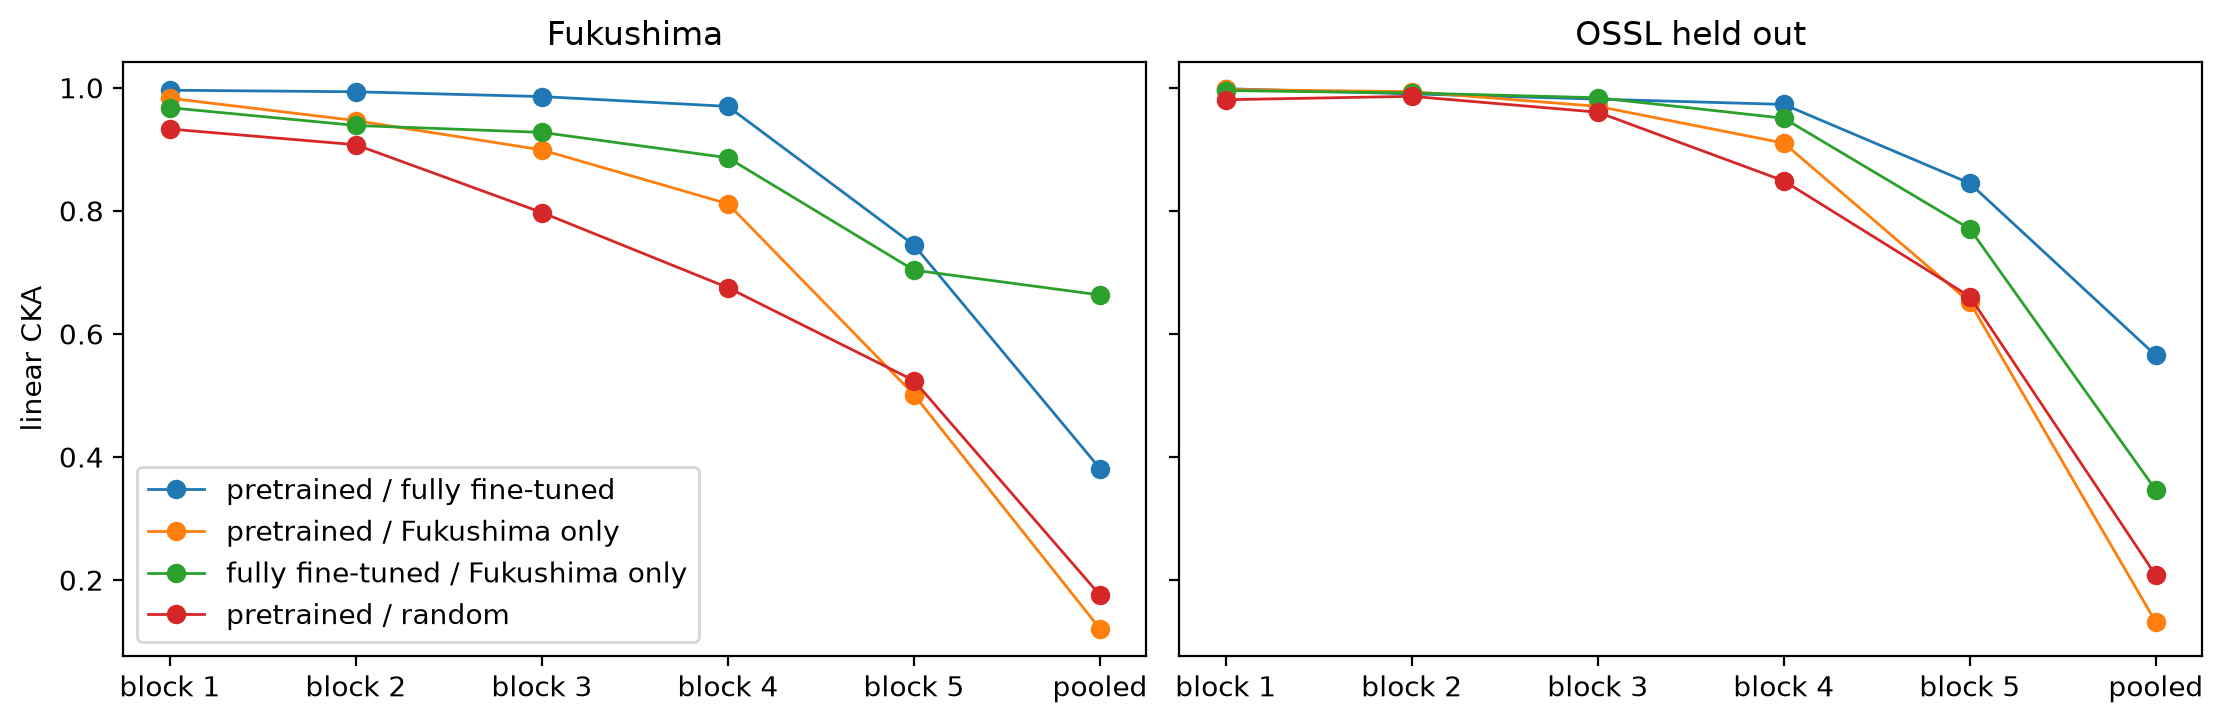

Fukushima  ...                    
        pretrained / fully fine-tuned  ... pretrained / random
block 1                         0.996  ...               0.981
block 2                         0.993  ...               0.986
block 3                         0.986  ...               0.960
block 4                         0.970  ...               0.849
block 5                         0.744  ...               0.661
pooled                          0.381  ...               0.208

[6 rows x 8 columns]

In [ ]:
#| fukudata
pairs = [('pretrained', 'fully fine-tuned'), ('pretrained', 'Fukushima only'), ('fully fine-tuned', 'Fukushima only'), ('pretrained', 'random')]
cka_m = pd.DataFrame({(d, f'{a} / {b}'): cka_layers(F[a, d], F[b, d]) for d in ('Fukushima', 'OSSL held out') for a, b in pairs}).drop('input')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout='constrained')
for ax, d in zip(axs, ('Fukushima', 'OSSL held out')):
    cka_m[d].plot(ax=ax, marker='o', lw=1, title=d)
    ax.set_ylabel('linear CKA')
axs[1].get_legend().remove()
cka_m.round(3)

## Distance from OSSL

`nn_ratio` at each layer of each model, with the 2,500 OSSL reference spectra as the reference set. The held-out OSSL spectra are the control: they come from the same population as the reference set:

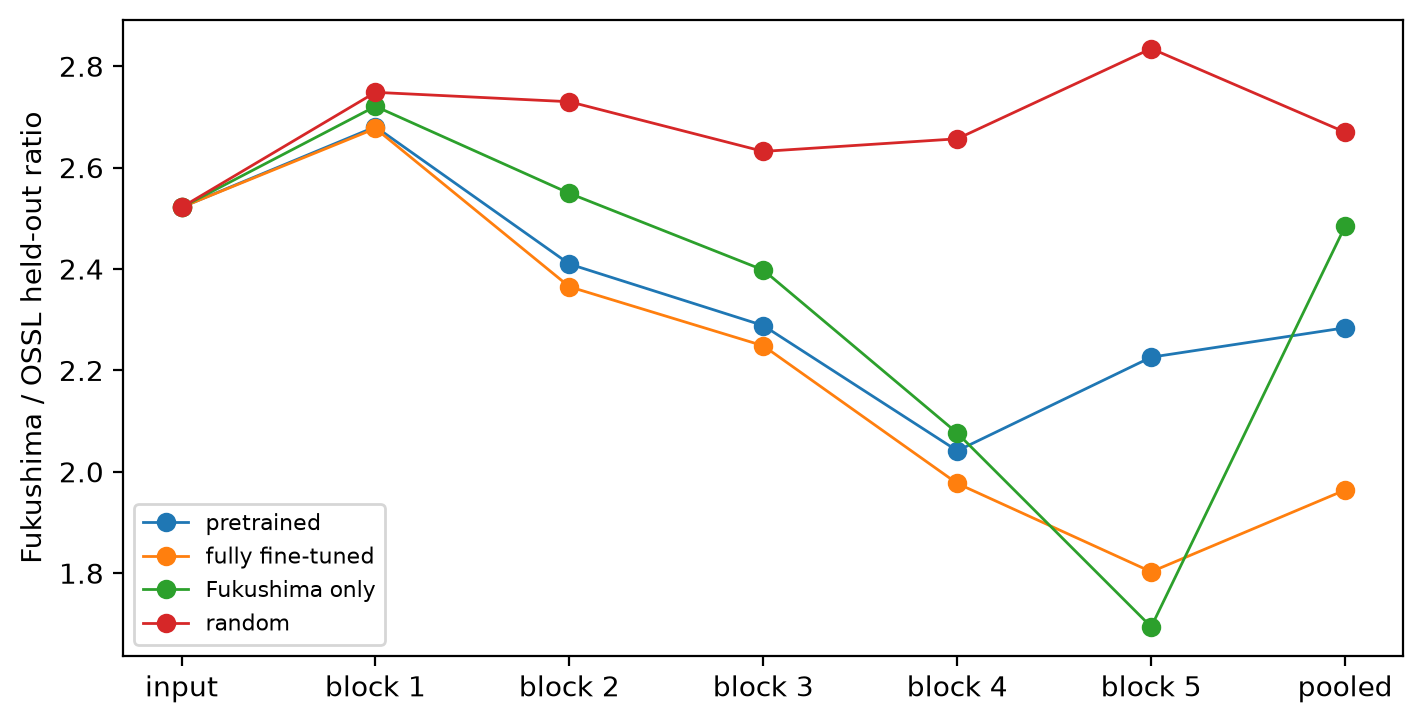

pretrained            ...        random          
        OSSL held out Fukushima  ... OSSL held out Fukushima
input            1.00      2.52  ...          1.00      2.52
block 1          1.00      2.67  ...          1.00      2.75
block 2          0.99      2.40  ...          1.01      2.77
block 3          0.99      2.27  ...          1.01      2.67
block 4          1.01      2.06  ...          1.01      2.68
block 5          0.99      2.20  ...          1.00      2.84
pooled           1.00      2.29  ...          1.00      2.66

[7 rows x 8 columns]

In [ ]:
#| fukudata
dist = pd.DataFrame({(m, d): {k: nn_ratio(F[m, 'OSSL ref'][k], F[m, d][k]) for k in layers}
                     for m in models for d in ('OSSL held out', 'Fukushima')})
fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
for m in models: ax.plot(layers, dist[m, 'Fukushima'] / dist[m, 'OSSL held out'], marker='o', lw=1, label=m)
ax.set_ylabel('Fukushima / OSSL held-out ratio'); ax.legend(fontsize=8)
dist.round(2)

## Bruker and Thermo spectra of the same soils

The 376 soils of `05_paired` with both Bruker and Thermo spectra, on the grid both instruments cover (650–3996 cm⁻¹), with the same preprocessing. CKA between the two instruments' representations of the same soils, at each layer of each model:

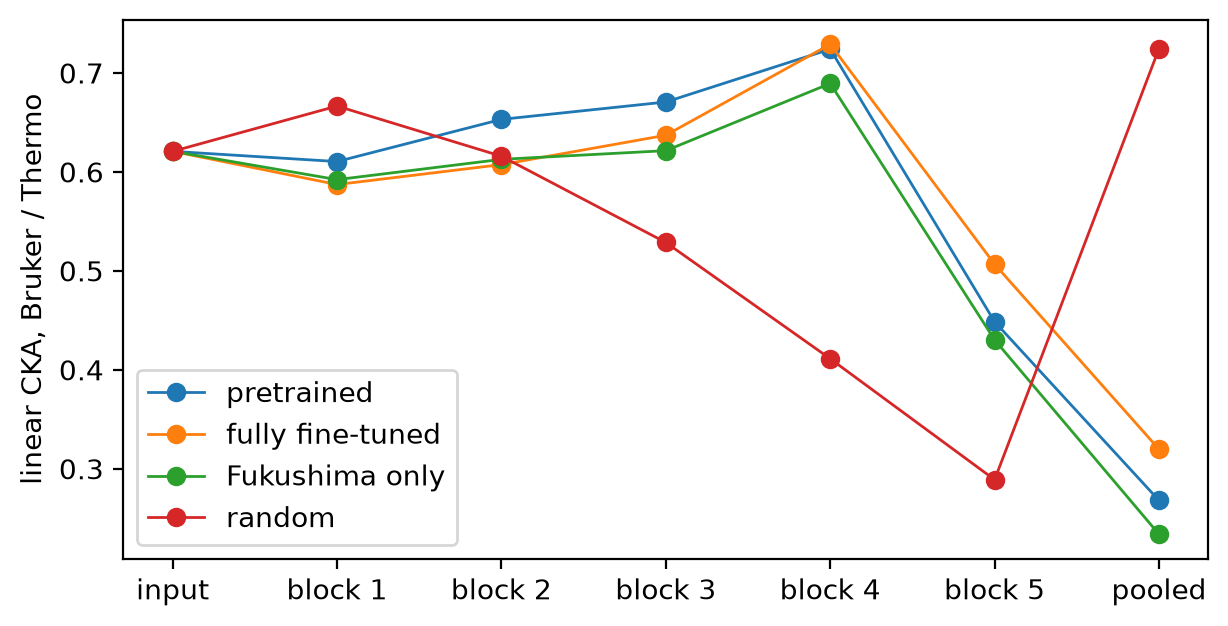

,pretrained,fully fine-tuned,Fukushima only,random
input,0.621,0.621,0.621,0.621
block 1,0.610,0.587,0.592,0.667
block 2,0.653,0.607,0.613,0.616
block 3,0.671,0.637,0.621,0.529
block 4,0.724,0.729,0.689,0.411
block 5,0.449,0.507,0.430,0.289
pooled,0.268,0.320,0.234,0.725


In [ ]:
#| fukudata
pw = np.arange(650, 3997, 2)
ids = [i for i in sorted(set(bruker_files()) & set(spa_files()), key=int) if i not in excluded]
br, th = load_bruker(pw, ids), load_fuku(pw, ids)
pre = preprocessings()['snv_d1']
Xb, Xt = pre.fit_transform(br.spectra), pre.fit_transform(th.spectra)
paired = pd.DataFrame({m: cka_layers(layer_features(model, Xb), layer_features(model, Xt)) for m, model in models.items()})
ax = paired.plot(marker='o', lw=1, figsize=(7, 3.5), ylabel='linear CKA, Bruker / Thermo')
paired.round(3)

## Kex in each layer

A `probe` at each layer of each model. For Fukushima, the probes train on the Fukushima training samples and are scored on the test set. For OSSL, they train on the 2,500 reference spectra and are scored on the 1,388 held-out spectra. The R² of `log1p(Kex)`:

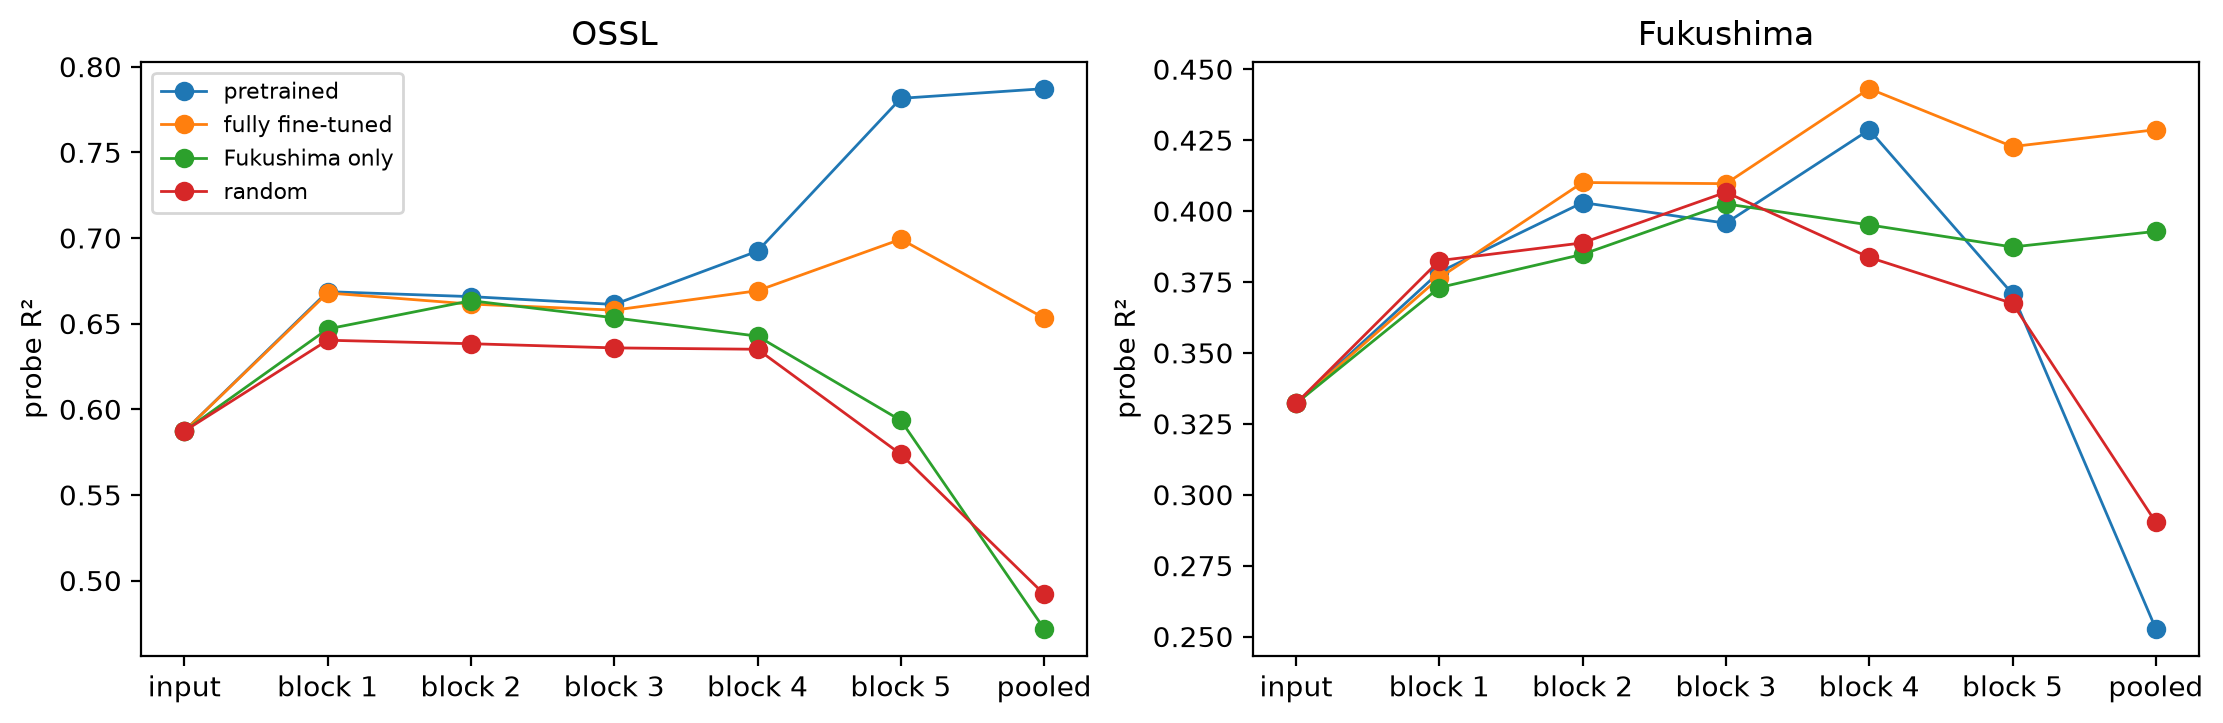

data,Fukushima,OSSL,Fukushima,OSSL,Fukushima,OSSL,Fukushima,OSSL
model,pretrained,pretrained,fully fine-tuned,fully fine-tuned,Fukushima only,Fukushima only,random,random
layer,,,,,,,,
input,0.332,0.587,0.332,0.587,0.332,0.587,0.332,0.587
block 1,0.378,0.669,0.376,0.668,0.373,0.647,0.383,0.640
block 2,0.403,0.666,0.410,0.661,0.385,0.663,0.389,0.638
block 3,0.396,0.661,0.410,0.658,0.403,0.653,0.407,0.636
block 4,0.429,0.692,0.443,0.669,0.395,0.643,0.384,0.635
block 5,0.371,0.782,0.423,0.699,0.387,0.593,0.367,0.574
pooled,0.253,0.787,0.429,0.653,0.393,0.472,0.290,0.492


In [ ]:
#| fukudata
rows = []
for m in models:
    for k in layers:
        Ff = F[m, 'Fukushima'][k]
        rows.append({'data': 'Fukushima', 'model': m, 'layer': k, **probe(Ff[~is_test], yf[~is_test], Ff[is_test], yf[is_test])})
        rows.append({'data': 'OSSL', 'model': m, 'layer': k, **probe(F[m, 'OSSL ref'][k], yo[o_ref], F[m, 'OSSL held out'][k], yo[o_new])})
pr = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), layout='constrained')
for ax, d in zip(axs, ('OSSL', 'Fukushima')):
    for m in models:
        s = pr[(pr.data == d) & (pr.model == m)]
        ax.plot(s.layer, s['R²'], marker='o', lw=1, label=m)
    ax.set_title(d); ax.set_ylabel('probe R²')
axs[0].legend(fontsize=8)
pr.pivot_table(index='layer', columns=['data', 'model'], values='R²', sort=False).round(3)

The correlation `r` of the same probes:

In [ ]:
#| fukudata
pr.pivot_table(index='layer', columns=['data', 'model'], values='r', sort=False).round(3)

data,Fukushima,OSSL,Fukushima,OSSL,Fukushima,OSSL,Fukushima,OSSL
model,pretrained,pretrained,fully fine-tuned,fully fine-tuned,Fukushima only,Fukushima only,random,random
layer,,,,,,,,
input,0.582,0.776,0.582,0.776,0.582,0.776,0.582,0.776
block 1,0.618,0.819,0.617,0.819,0.614,0.811,0.619,0.802
block 2,0.635,0.822,0.640,0.820,0.620,0.819,0.624,0.804
block 3,0.629,0.818,0.640,0.816,0.635,0.811,0.638,0.805
block 4,0.657,0.836,0.666,0.822,0.632,0.804,0.621,0.799
block 5,0.614,0.886,0.651,0.838,0.626,0.773,0.607,0.765
pooled,0.504,0.888,0.657,0.810,0.630,0.691,0.542,0.707


## Findings

On Fukushima, every layer of every model holds about the same amount of linearly readable Kex information, even the model with random weights. A ridge probe on the preprocessed spectra gives a test R² of 0.33 (r 0.58). Probes on blocks 1 to 5 of all four models give 0.37 to 0.44 (r 0.61 to 0.67). The random model's best block gives 0.41. The best probe is block 4 of the fully fine-tuned model, at 0.44. A probe on block 4 of the frozen pretrained model gives 0.43 (r 0.66), the same as the fully fine-tuned model's own head (0.43, r 0.66). With 341 test samples, one R² has a sampling standard deviation of about 0.04, so most of these differences are within noise. In these layers, neither pretraining on OSSL nor training on Fukushima produces features that hold clearly more Kex information than random convolutions do.

On OSSL, learning makes a large difference. The pretrained model's probes rise from 0.59 at the input to 0.79 at the pooled features, while the random model's stay between 0.49 and 0.64. That gain does not carry over to Fukushima. There, the pretrained model's pooled features give 0.25, less than the spectra themselves. Block 5 and the global pool are where the pretrained model turns general features into OSSL-specific ones.

The CKA comparisons point to the same split. Fine-tuning leaves blocks 1 to 4 almost unchanged (CKA with the pretrained model 0.97 or more on Fukushima spectra) and changes block 5 (0.74) and the pooled features (0.38). The Fukushima-only model is close to the pretrained model in block 1 (0.98) and moves away with depth: 0.81 in block 4, 0.50 in block 5 and 0.12 in the pooled features. The random model is also close to the pretrained model in the early blocks (0.93 in block 1), so a high CKA there mostly reflects the architecture. In block 4, the Fukushima-only model is closer to the pretrained model (0.81) than the random model is (0.68). Training on either dataset finds partly the same mid-level features.

Fukushima spectra sit outside OSSL in every layer of every model. At the input, the median distance from a Fukushima spectrum to its nearest OSSL spectrum is 2.5 times that of a held-out OSSL spectrum, whose ratio is 1.0. The random model keeps the ratio at 2.7 to 2.8 through all blocks. The trained models bring it down with depth, to about 2.0 in block 4 and 1.7 to 2.2 in block 5. None brings Fukushima among the OSSL spectra. The pretrained model's pooled features push it back out, to 2.3.

For the 376 soils with both Bruker and Thermo spectra, the CKA between the two instruments' representations is 0.62 at the input. In the three trained models it dips slightly in block 1 (0.59 to 0.61), rises to 0.69 to 0.73 in block 4, then falls to 0.43 to 0.51 in block 5 and 0.23 to 0.32 in the pooled features. Blocks 2 to 4 make the two instruments' spectra of a soil more alike, and block 5 and the pool make them less alike. In the random model the CKA falls from block 1 to 0.29 in block 5, but its pooled features give 0.73. With random weights, the global average probably keeps mostly an overall intensity that both instruments share. This was not checked.

The Fukushima Kex ceiling of about 0.43 is reached by linear probes on random features, by frozen OSSL features and by the end-to-end models alike. So the limit lies in the Fukushima data rather than in the features the CNN learns. `08_learning_curve` shows which part of the data: every model still gains R² with more training samples at 1,047, so the number of samples limits the scores. In the pretrained model, block 4 is the best candidate layer to transfer from. Its probe is the best of that model on Fukushima, although within noise of the others. It brings Fukushima closest to OSSL, and it makes the two instruments most alike.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()